In [5]:
from circuit_benchmarks import Transport_SQRB_Experiment
from selene_sim import DepolarizingErrorModel, Stim, Quest
from pecos_selene import qsystem_model_alpha # requires pecos_selene

In [3]:
# select parameters and build experiment

n_qubits = 16
seq_lengths = [8, 32, 128]
seq_reps = 10
filename = 'exp_transport_SQRB_example.p'

qubit_transport_depths = {
    0: 1,
    1: 1,
    2: 1,
    3: 1,
    4: 2,
    5: 2,
    6: 2,
    7: 2,
    8: 4,
    9: 4,
    10: 4,
    11: 4,
    12: 8,
    13: 8,
    14: 8,
    15: 8
}

exp = Transport_SQRB_Experiment(n_qubits, seq_lengths, seq_reps, qubit_transport_depths, filename=filename)
#exp.options['measure_leaked'] = True # False by default
exp.add_settings()

In [ ]:
# or load an existing experiment from working directory

filename = 'exp_transport_SQRB_example.p'
exp = Transport_SQRB_Experiment.load(filename)

Having setup our transport SQRB experiment, we can now either simulate using a local simulator or submit to a hardware or emulator backend.

### Run local simulation using Selene

In [4]:
# Setup simple error model

error_model = DepolarizingErrorModel(
    random_seed=1234,
    # single qubit gate error rate
    p_1q=1e-4,
    # two qubit gate error rate
    p_2q=1e-2,
    # set state preparation and measurement error rates to 0
    p_meas=0,
    p_init=0,
)

In [7]:
# Or use hardware realistic noise model

error_model = qsystem_model_alpha(random_seed=123)
error_model.coherent_dephasing = False

c:\Users\Karl.Mayer\myenv\Lib\site-packages\pecos_selene\error_models\named.py:28: UserWarning: 


* Crosstalk includes no unleak term, but is otherwise fairly realistic.

* Leakage and memory error are implemented as in H1/H2, but it is expected these will be different in Helios.

* Calibration of the noise parameter values for Helios is still ongoing.
  warnings.warn(msg)


In [8]:
# simulate experiment

shots = 100
simulator = Stim()

exp.sim(shots, error_model=error_model, simulator=simulator)

Simulating ...
1/30 circuits complete
2/30 circuits complete
3/30 circuits complete
4/30 circuits complete
5/30 circuits complete
6/30 circuits complete
7/30 circuits complete
8/30 circuits complete
9/30 circuits complete
10/30 circuits complete
11/30 circuits complete
12/30 circuits complete
13/30 circuits complete
14/30 circuits complete
15/30 circuits complete
16/30 circuits complete
17/30 circuits complete
18/30 circuits complete
19/30 circuits complete
20/30 circuits complete
21/30 circuits complete
22/30 circuits complete
23/30 circuits complete
24/30 circuits complete
25/30 circuits complete
26/30 circuits complete
27/30 circuits complete
28/30 circuits complete
29/30 circuits complete
30/30 circuits complete


### Submit to Quantinuum Hardware or Emulator backend using Nexus

In [4]:
# Choose domain and login to Nexus

import qnexus

### uncomment lines below if submitting to QA ###
#from qnexus.config import CONFIG
#CONFIG.domain = "qa.myqos.com"

qnexus.login_with_credentials()

🌐 Browser log in initiated.


╭────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                        │
│         Confirm that the browser shows the following code and click 'allow device':    │
│                                                                                        │
│                                      PTbSpK                                            │
│                                                                                        │
╰────────────────────────────────────────────────────────────────────────────────────────╯

Browser didn't open automatically? Use this link: https://qa.myqos.com/auth/device/browser?otp=PTbSpKQWNwtLyHty48it0i1UbQVVlSWbbkN14Gq7k_14wZLRrt1Kypx_jNpaeTAqn9Ebf2iBn_--hgcbSc2Sng
✅ Successfully logged in as karl.mayer@quantinuum.com using the browser.


In [5]:
# choose nexus project and setup quantinuum backend config

project = qnexus.projects.get_or_create(name='transport-SQRB-example-project')
qnexus.context.set_active_project(project)

backend_config = qnexus.QuantinuumConfig(device_name='Helios-1E', simulator='stabilizer', max_cost=1000000)

In [6]:
# submit experiment. Returns a qnexus ExecuteJobRef

shots = 100

execute_job_ref = exp.submit(shots, backend_config)

In [11]:
# inspect status of the execution job

qnexus.jobs.status(execute_job_ref)

JobStatus(status=<StatusEnum.COMPLETED: 'Circuit has completed. Results are ready.'>, message='The job is completed.', error_detail=None, completed_time=datetime.datetime(2025, 5, 28, 17, 13, 6, 26862, tzinfo=datetime.timezone.utc), queued_time=None, submitted_time=datetime.datetime(2025, 5, 28, 16, 51, 32, 836542, tzinfo=datetime.timezone.utc), running_time=datetime.datetime(2025, 5, 28, 16, 52, 4, 993776, tzinfo=datetime.timezone.utc), cancelled_time=None, error_time=None, queue_position=None)

In [12]:
# retrieve results (once execution job has completed)

exp.retrieve(execute_job_ref)

### Analyze experiment results

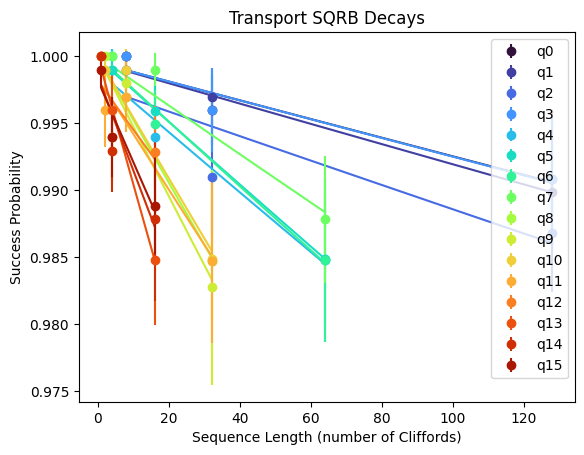

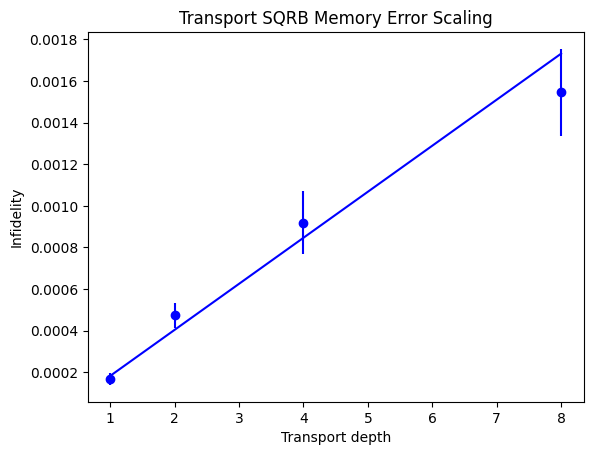

Depth-1 Linear Memory Error:
0.00022 +/- 3e-05
------------------------------


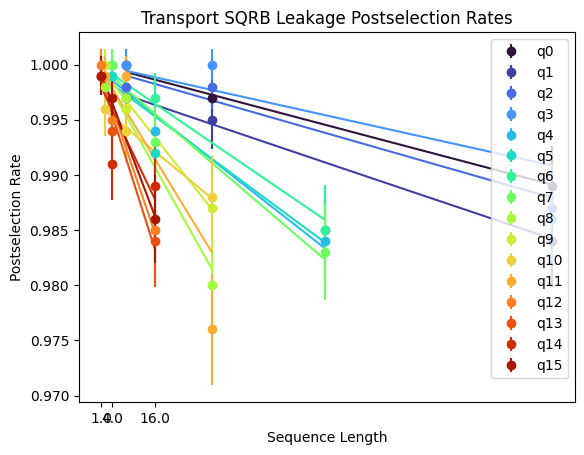

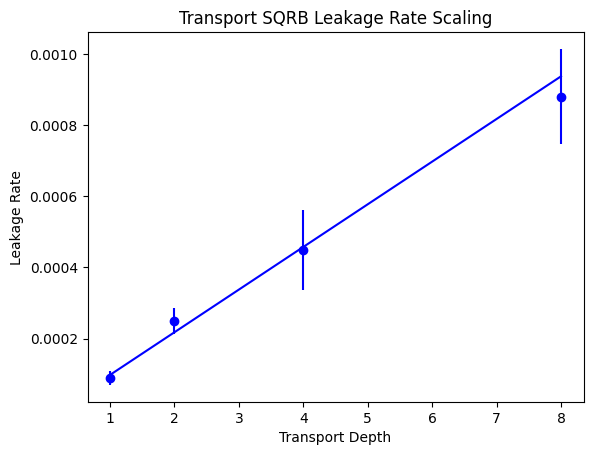

Depth-1 Linear Leakage Error:
0.00012 +/- 1e-05
------------------------------
Average Infidelities
------------------------------
qubit 0: 0.000156 +/- 4.3e-05
qubit 1: 0.000186 +/- 3.5e-05
qubit 2: 0.000185 +/- 4.2e-05
qubit 3: 0.000143 +/- 3.8e-05
qubit 4: 0.000485 +/- 0.000108
qubit 5: 0.000479 +/- 8.4e-05
qubit 6: 0.000466 +/- 0.000102
qubit 7: 0.000463 +/- 7.2e-05
qubit 8: 0.001058 +/- 0.000209
qubit 9: 0.000938 +/- 0.000227
qubit 10: 0.000726 +/- 0.000141
qubit 11: 0.000956 +/- 0.000212
qubit 12: 0.001325 +/- 0.000246
qubit 13: 0.001988 +/- 0.000312
qubit 14: 0.001389 +/- 0.000428
qubit 15: 0.001478 +/- 0.000263
------------------------------
Transport Depth 1 Average: 0.000168 +/- 2.8e-05
Transport Depth 2 Average: 0.000473 +/- 5.8e-05
Transport Depth 4 Average: 0.00092 +/- 0.000151
Transport Depth 8 Average: 0.001545 +/- 0.000209

Qubit Average Leakge Rates:
Transport Depth 1: 9e-05 +/- 2e-05
Transport Depth 2: 0.000249 +/- 3.6e-05
Transport Depth 4: 0.000449 +/- 0.000113
Tran

In [9]:
exp.analyze_results()

In [7]:
# save experiment object to working directory

exp.save()